# 03 — Modélisation, évaluation, ablations et équité

Modèles comparés (ML classique uniquement) : **Zero-R**, Naïve Bayes multinomial, KNN, Arbre de décision, Random Forest, Linear SVC. Réglage par `GridSearchCV` (validation croisée stratifiée) sur des `Pipeline(préprocesseur + modèle)`.

**Choix du champion** : sur le score de *validation croisée* (F1 macro), jamais sur le jeu de test.

In [1]:
import sys, json, warnings; warnings.filterwarnings('ignore')
sys.path.append('../src')
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from features import build_preprocessor, TARGET, SENSITIVE_COLS

sns.set_theme(style='whitegrid')
train = pd.read_csv('../data/processed/train.csv', keep_default_na=False, na_values=[''])
test = pd.read_csv('../data/processed/test.csv', keep_default_na=False, na_values=[''])
for d in (train, test): d['HaveWorkedWith'] = d['HaveWorkedWith'].fillna('')
X_train, y_train = train.drop(columns=TARGET), train[TARGET]
X_test, y_test = test.drop(columns=TARGET), test[TARGET]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# FAST_MODE : le réglage des hyperparamètres se fait sur un sous-échantillon (plus rapide).
# Le meilleur jeu d'hyperparamètres est ensuite ré-entraîné sur TOUT le train.
FAST_MODE, TUNE_N = True, 20000
X_tune = X_train.sample(TUNE_N, random_state=42) if FAST_MODE else X_train
y_tune = y_train.loc[X_tune.index]
X_train.shape, X_test.shape

((58766, 13), (14692, 13))

## 1. Définition des modèles et des grilles

In [2]:
models = {
    'Zero-R (baseline)': (DummyClassifier(strategy='most_frequent'), {}, False),
    'Multinomial Naive Bayes': (MultinomialNB(), {'clf__alpha': [0.1, 1.0, 5.0]}, True),
    'K-Nearest Neighbors': (KNeighborsClassifier(n_jobs=-1), {'clf__n_neighbors': [15, 31, 51]}, False),
    'Decision Tree': (DecisionTreeClassifier(random_state=42),
                      {'clf__max_depth': [5, 8, 12], 'clf__min_samples_leaf': [1, 20, 50]}, False),
    'Random Forest': (RandomForestClassifier(random_state=42, n_jobs=-1),
                      {'clf__n_estimators': [100, 200], 'clf__max_depth': [10, 20]}, False),
    'Linear SVC': (LinearSVC(random_state=42, max_iter=5000), {'clf__C': [0.1, 1, 10]}, False),
}

def make_pipe(clf, nonneg=False, **prep_kwargs):
    return Pipeline([('prep', build_preprocessor(nonneg=nonneg, **prep_kwargs)), ('clf', clone(clf))])

## 2. Réglage (GridSearchCV) puis ré-entraînement sur tout le train

In [3]:
fitted, cv_scores, best_params = {}, {}, {}
for name, (clf, grid, nonneg) in models.items():
    pipe = make_pipe(clf, nonneg)
    if grid:
        gs = GridSearchCV(pipe, grid, cv=cv, scoring='f1_macro', n_jobs=-1, refit=False)
        gs.fit(X_tune, y_tune)
        best_params[name], cv_scores[name] = gs.best_params_, gs.best_score_
        pipe.set_params(**gs.best_params_)
    else:
        best_params[name], cv_scores[name] = {}, np.nan
    fitted[name] = pipe.fit(X_train, y_train)
    print(f'{name:26s} CV F1-macro = {cv_scores[name]:.4f}  {best_params[name]}')

Zero-R (baseline)          CV F1-macro = nan  {}


Multinomial Naive Bayes    CV F1-macro = 0.8555  {'clf__alpha': 5.0}


K-Nearest Neighbors        CV F1-macro = 0.8597  {'clf__n_neighbors': 31}


Decision Tree              CV F1-macro = 0.9770  {'clf__max_depth': 12, 'clf__min_samples_leaf': 1}


Random Forest              CV F1-macro = 0.9544  {'clf__max_depth': 20, 'clf__n_estimators': 200}


Linear SVC                 CV F1-macro = 1.0000  {'clf__C': 0.1}


## 3. Évaluation sur le jeu de test

In [4]:
def scores_of(model, X):
    return model.decision_function(X) if hasattr(model, 'decision_function') else model.predict_proba(X)[:, 1]

rows = []
for name, m in fitted.items():
    pred = m.predict(X_test)
    auc = np.nan if name.startswith('Zero-R') else roc_auc_score(y_test, scores_of(m, X_test))
    rows.append({'Modèle': name,
                 'CV F1-macro': cv_scores[name],
                 'Accuracy': accuracy_score(y_test, pred),
                 'Précision (1)': precision_score(y_test, pred),
                 'Rappel (1)': recall_score(y_test, pred),
                 'F1 (1)': f1_score(y_test, pred),
                 'F1 (0)': f1_score(y_test, pred, pos_label=0),
                 'F1 macro': f1_score(y_test, pred, average='macro'),
                 'ROC-AUC': auc})
results = pd.DataFrame(rows).sort_values('F1 macro', ascending=False).reset_index(drop=True)
results.round(4)

,Modèle,CV F1-macro,Accuracy,Précision (1),Rappel (1),F1 (1),F1 (0),F1 macro,ROC-AUC
0,Linear SVC,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,Decision Tree,0.9770,0.9990,0.9991,0.9991,0.9991,0.9990,0.9990,0.9994
2,Random Forest,0.9544,0.9742,0.9699,0.9824,0.9761,0.9720,0.9740,0.9977
3,K-Nearest Neighbors,0.8597,0.8716,0.9575,0.7958,0.8692,0.8739,0.8715,0.9655
4,Multinomial Naive Bayes,0.8555,0.8543,0.8461,0.8903,0.8676,0.8381,0.8529,0.9404
5,Zero-R (baseline),NaN,0.5362,0.5362,1.0000,0.6981,0.0000,0.3490,NaN


In [5]:
champion = results.loc[results['CV F1-macro'].idxmax(), 'Modèle']   # choisi sur la CV, pas sur le test
print('Champion (meilleur F1-macro en validation croisée) :', champion)
best = fitted[champion]

Champion (meilleur F1-macro en validation croisée) : Linear SVC


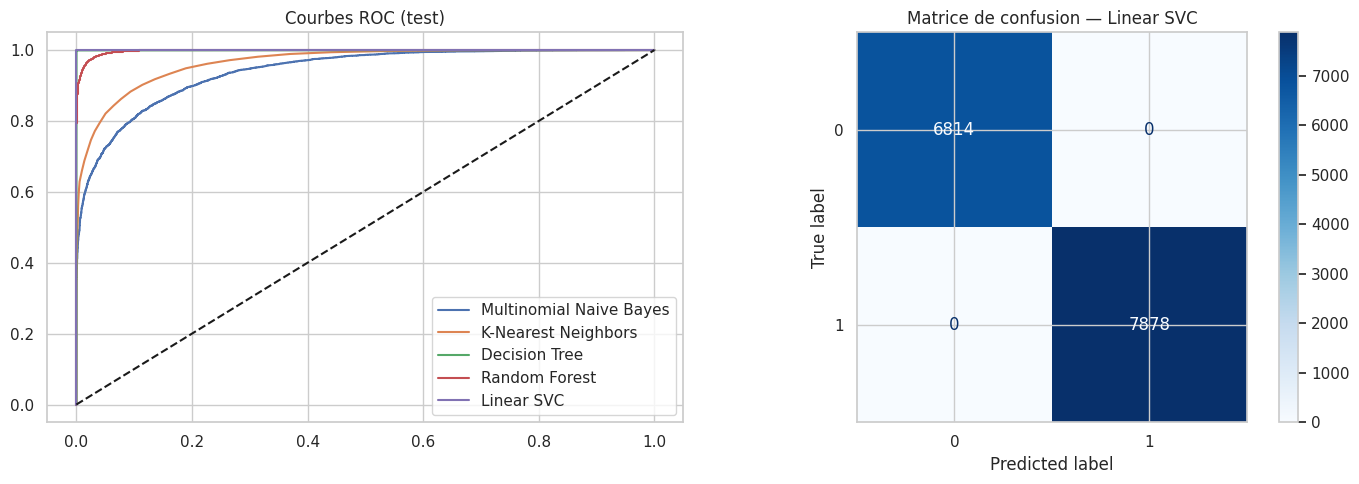

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, m in fitted.items():
    if name.startswith('Zero-R'): continue
    fpr, tpr, _ = roc_curve(y_test, scores_of(m, X_test)); axes[0].plot(fpr, tpr, label=name)
axes[0].plot([0, 1], [0, 1], 'k--'); axes[0].set_title('Courbes ROC (test)'); axes[0].legend()
ConfusionMatrixDisplay.from_predictions(y_test, best.predict(X_test), ax=axes[1], cmap='Blues')
axes[1].set_title(f'Matrice de confusion — {champion}'); plt.tight_layout(); plt.show()

## 4. Ce que le modèle utilise réellement

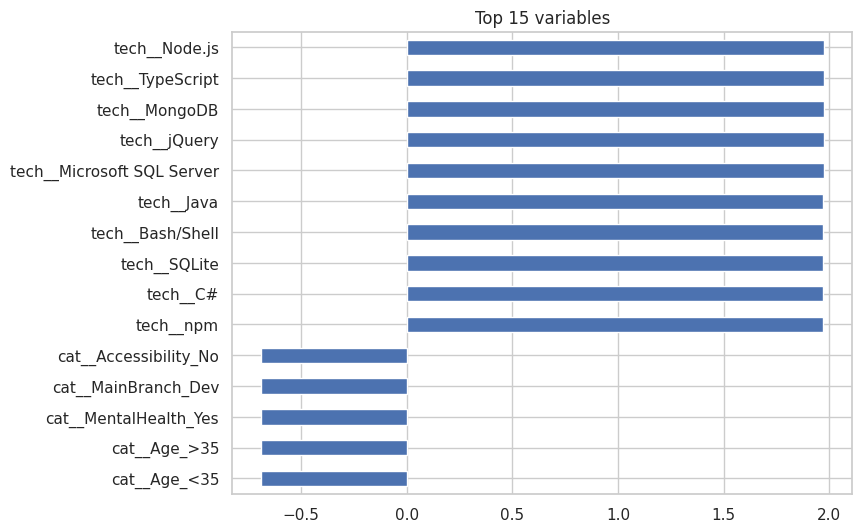

In [7]:
clf = best.named_steps['clf']
names = best.named_steps['prep'].get_feature_names_out()
if hasattr(clf, 'coef_'):
    imp = pd.Series(clf.coef_.ravel(), index=names)
    imp = imp.reindex(imp.abs().sort_values(ascending=False).index)
elif hasattr(clf, 'feature_importances_'):
    imp = pd.Series(clf.feature_importances_, index=names).sort_values(ascending=False)
else:
    imp = None
if imp is not None:
    imp.head(15).iloc[::-1].plot.barh(figsize=(8, 6)); plt.title('Top 15 variables'); plt.show()

## 5. Ablations — d'où vient la performance ?

On ré-entraîne le champion en retirant des variables. `ComputerSkills` est très corrélée à la cible : on mesure ce qu'il reste sans elle.

In [8]:
ablations = {
    'Toutes les variables': (),
    'Sans ComputerSkills': ('ComputerSkills',),
    'Sans ComputerSkills ni technologies': ('ComputerSkills', 'HaveWorkedWith'),
    'Sans Employment': ('Employment',),
    'Sans PreviousSalary': ('PreviousSalary',),
    f'Sans variables sensibles {tuple(SENSITIVE_COLS)}': tuple(SENSITIVE_COLS),
}
clf0, _, nonneg0 = models[champion]
rows = []
for label, drop in ablations.items():
    p = make_pipe(clf0, nonneg0, drop_cols=drop)
    p.set_params(**best_params[champion]).fit(X_train, y_train)
    pred = p.predict(X_test)
    rows.append({'Scénario': label, 'Accuracy': accuracy_score(y_test, pred),
                 'F1 (1)': f1_score(y_test, pred), 'F1 (0)': f1_score(y_test, pred, pos_label=0),
                 'F1 macro': f1_score(y_test, pred, average='macro')})
ablation_df = pd.DataFrame(rows)
ablation_df.round(4)

,Scénario,Accuracy,F1 (1),F1 (0),F1 macro
0,Toutes les variables,1.0000,1.0000,1.0000,1.0000
1,Sans ComputerSkills,1.0000,1.0000,1.0000,1.0000
2,Sans ComputerSkills ni technologies,0.5744,0.6718,0.3949,0.5333
3,Sans Employment,1.0000,1.0000,1.0000,1.0000
4,Sans PreviousSalary,1.0000,1.0000,1.0000,1.0000
5,"Sans variables sensibles ('Age', 'Gender', 'Me...",1.0000,1.0000,1.0000,1.0000


## 6. Diagnostic — pourquoi ~100 % ?

Un score parfait est un **signal d'alarme** : soit fuite de données, soit cible définie par une règle. Aucune fuite ici (la cible n'est pas dans `X`, le préprocesseur est ajusté par pli). Les ablations montrent que tout le signal vient de la liste de technologies `HaveWorkedWith`. On cherche donc la règle : une régression logistique sur *toutes* les technologies donne des poids très élevés à quelques technologies seulement.

In [9]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from features import split_techs

full = pd.concat([train, test], ignore_index=True)
cv_all = CountVectorizer(tokenizer=split_techs, token_pattern=None, lowercase=False, binary=True)
T = cv_all.fit_transform(full['HaveWorkedWith'])
lr = LogisticRegression(C=10, max_iter=3000).fit(T, full[TARGET])
w = pd.Series(lr.coef_[0], index=cv_all.get_feature_names_out()).sort_values(ascending=False)
key_techs = list(w[w > 5].index)
print(len(key_techs), 'technologies à poids élevé :', key_techs)

full['n_key'] = full['HaveWorkedWith'].apply(lambda s: len(set(split_techs(s)) & set(key_techs)))
diag = pd.crosstab(full['n_key'], full[TARGET]).rename(columns={0: 'Employed=0', 1: 'Employed=1'})
diag

10 technologies à poids élevé : ['Microsoft SQL Server', 'npm', 'jQuery', 'TypeScript', 'MongoDB', 'SQLite', 'Bash/Shell', 'Node.js', 'C#', 'Java']


Employed,Employed=0,Employed=1
n_key,,
0,6381,0
1,12704,0
2,14983,0
3,0,14013
4,0,11048
5,0,7178
6,0,3975
7,0,1980
8,0,852


In [10]:
thr = full.groupby('n_key')[TARGET].mean()
threshold = int(thr[thr > 0.5].index.min())
rule = (full['n_key'] >= threshold).astype(int)
print(f'Règle : Employed = 1  <=>  le candidat maîtrise au moins {threshold} des {len(key_techs)} technologies ci-dessus')
print('Exactitude de cette règle sur les', len(full), 'lignes :', round((rule == full[TARGET]).mean(), 4))
diag.to_csv('../models/diagnostic.csv')

Règle : Employed = 1  <=>  le candidat maîtrise au moins 3 des 10 technologies ci-dessus
Exactitude de cette règle sur les 73458 lignes : 1.0


**Conclusion** : la cible `Employed` est **une fonction déterministe** de `HaveWorkedWith` (≥ k technologies « clés »). Les modèles qui voient cette liste retrouvent la règle (≈ 100 %) ; ce n'est pas la preuve qu'on prédit l'employabilité réelle, mais que le jeu de données contient une étiquette construite artificiellement à partir de cette variable. À mentionner explicitement dans le rapport.

## 7. Comparaison « honnête » : profil seul (sans technologies ni `ComputerSkills`)

On ré-évalue tous les modèles (mêmes hyperparamètres) sans les variables qui encodent la règle.

In [11]:
drop_prof = ('ComputerSkills', 'HaveWorkedWith')
rows = []
for name, (clf, grid, nonneg) in models.items():
    p = make_pipe(clf, nonneg, drop_cols=drop_prof).set_params(**best_params[name]).fit(X_train, y_train)
    pred = p.predict(X_test)
    auc = np.nan if name.startswith('Zero-R') else roc_auc_score(y_test, scores_of(p, X_test))
    rows.append({'Modèle': name, 'Accuracy': accuracy_score(y_test, pred), 'F1 (1)': f1_score(y_test, pred),
                 'F1 (0)': f1_score(y_test, pred, pos_label=0), 'F1 macro': f1_score(y_test, pred, average='macro'),
                 'ROC-AUC': auc})
profile_df = pd.DataFrame(rows).sort_values('F1 macro', ascending=False).reset_index(drop=True)
profile_df.to_csv('../models/profile_only_results.csv', index=False)
profile_df.round(4)

,Modèle,Accuracy,F1 (1),F1 (0),F1 macro,ROC-AUC
0,K-Nearest Neighbors,0.5660,0.6372,0.4602,0.5487,0.5776
1,Random Forest,0.5813,0.6740,0.4148,0.5444,0.6020
2,Multinomial Naive Bayes,0.5743,0.6629,0.4227,0.5428,0.5916
3,Linear SVC,0.5744,0.6718,0.3949,0.5333,0.5929
4,Decision Tree,0.5709,0.6727,0.3772,0.5250,0.5678
5,Zero-R (baseline),0.5362,0.6981,0.0000,0.3490,NaN


Sans la liste de technologies, les modèles restent proches de la baseline Zero-R : formation, pays, expérience, salaire et attributs sensibles portent très peu d'information sur `Employed`.

## 8. Analyse d'équité (attributs sensibles)

Le jeu contient `Gender`, `Age`, `MentalHealth`, `Accessibility`. Prédire l'« employabilité » avec de tels attributs est éthiquement délicat : on compare ici le **taux de prédictions positives** et les **taux d'erreur par groupe**.

⚠️ Le champion retrouvant la règle sur les technologies, ses erreurs sont nulles pour tous les groupes ; l'écart de taux prédit entre groupes reflète donc **l'écart déjà présent dans l'étiquette** (ex. Gender), pas un biais du modèle.

In [12]:
pred = best.predict(X_test)
audit = X_test.assign(y=y_test.values, pred=pred)

def group_metrics(g):
    pos, neg = g[g.y == 1], g[g.y == 0]
    return pd.Series({'n': len(g), 'taux réel': g.y.mean(), 'taux prédit': g.pred.mean(),
                      'accuracy': (g.y == g.pred).mean(),
                      'TPR (rappel)': (pos.pred == 1).mean() if len(pos) else np.nan,
                      'FPR': (neg.pred == 1).mean() if len(neg) else np.nan})

fair = pd.concat({c: audit.groupby(c).apply(group_metrics) for c in SENSITIVE_COLS})
fair.round(3)

n  taux réel  taux prédit  accuracy  \
Age           <35         9518.0      0.543        0.543       1.0   
              >35         5174.0      0.524        0.524       1.0   
Gender        Man        13703.0      0.542        0.542       1.0   
              NonBinary    268.0      0.504        0.504       1.0   
              Woman        721.0      0.447        0.447       1.0   
MentalHealth  No         11401.0      0.528        0.528       1.0   
              Yes         3291.0      0.565        0.565       1.0   
Accessibility No         14264.0      0.535        0.535       1.0   
              Yes          428.0      0.561        0.561       1.0   

                         TPR (rappel)  FPR  
Age           <35                 1.0  0.0  
              >35                 1.0  0.0  
Gender        Man                 1.0  0.0  
              NonBinary           1.0  0.0  
              Woman               1.0  0.0  
MentalHealth  No                  1.0  0.0  
              Yes                 1.0  0.0  
Accessibility No                  1.0  0.0  
              Yes                 1.0  0.0

In [13]:
# Écart de taux de prédiction positive entre groupes (parité démographique)
for c in SENSITIVE_COLS:
    r = audit.groupby(c)['pred'].mean()
    print(f'{c:14s} min={r.min():.3f}  max={r.max():.3f}  écart={r.max() - r.min():.3f}')

Age            min=0.524  max=0.543  écart=0.019
Gender         min=0.447  max=0.542  écart=0.095
MentalHealth   min=0.528  max=0.565  écart=0.037
Accessibility  min=0.535  max=0.561  écart=0.025


## 9. Sauvegarde des artefacts pour l'application

In [14]:
joblib.dump(best, '../models/best_model.pkl')   # Pipeline complet : préprocesseur + modèle
results.to_csv('../models/results.csv', index=False)
ablation_df.to_csv('../models/ablation.csv', index=False)
fair.reset_index().rename(columns={'level_0': 'attribut'}).to_csv('../models/fairness.csv', index=False)
meta = {'champion': champion, 'best_params': best_params[champion],
        'technologies': list(best.named_steps['prep'].named_transformers_['tech'].get_feature_names_out()),
        'countries': sorted(train['Country'].unique().tolist()),
        'target_rate': float(y_train.mean()), 'n_train': int(len(train)), 'n_test': int(len(test))}
json.dump(meta, open('../models/meta.json', 'w'), ensure_ascii=False, indent=2)
print('Artefacts sauvegardés dans models/')

Artefacts sauvegardés dans models/
